<a href="https://colab.research.google.com/github/mpakaBrice/analyse-ventes-ecommerce-kazakhstan/blob/main/projet_3_analyse.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1 . Importation des bibliothèques + chargement des données

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
df = pd.read_parquet("/content/kz_clean.parquet")

In [ ]:
df

,event_time,order_id,product_id,category_id,category_code,brand,price,user_id,category_main,date,month,weekday,hour
0,2020-04-24 11:50:39,2294359932054536986,1515966223509089906,2268105426648170900,electronics.tablet,samsung,162.01,1515915625441993984,electronics,2020-04-24,2020-04,Friday,11
1,2020-04-24 14:37:43,2294444024058086220,2273948319057183658,2268105430162997728,electronics.audio.headphone,huawei,77.52,1515915625447879434,electronics,2020-04-24,2020-04,Friday,14
2,2020-04-24 19:16:21,2294584263154074236,2273948316817424439,2268105471367840086,unknown,karcher,217.57,1515915625443148002,unknown,2020-04-24,2020-04,Friday,19
3,2020-04-26 08:45:57,2295716521449619559,1515966223509261697,2268105442636858090,furniture.kitchen.table,maestro,39.33,1515915625450382722,furniture,2020-04-26,2020-04,Sunday,8
4,2020-04-26 09:33:47,2295740594749702229,1515966223509104892,2268105428166508982,electronics.smartphone,apple,1387.01,1515915625448766480,electronics,2020-04-26,2020-04,Sunday,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2609397,2020-11-21 10:10:01,2388440981134693942,1515966223526602848,2268105428166508982,electronics.smartphone,oppo,138.87,1515915625514888605,electronics,2020-11-21,2020-11,Saturday,10
2609398,2020-11-21 10:10:13,2388440981134693943,1515966223509089282,2268105428166508982,electronics.smartphone,apple,418.96,1515915625514891148,electronics,2020-11-21,2020-11,Saturday,10
2609399,2020-11-21 10:10:30,2388440981134693944,1515966223509089917,2268105402447037312,appliances.personal.scales,vitek,12.48,1515915625514834281,appliances,2020-11-21,2020-11,Saturday,10
2609400,2020-11-21 10:10:30,2388440981134693944,2273948184839454837,2268105440371933882,unknown,moulinex,41.64,1515915625514834281,unknown,2020-11-21,2020-11,Saturday,10


## 2. Vue d'ensemble : les chiffres clés

**Ce qu'on cherche :** les grands chiffres de l'activité, qui serviront de KPI en haut du tableau de bord.

- **CA total** : somme de tous les prix
- **Nombre de commandes** : nombre d'`order_id` différents
- **Panier moyen** : CA / nombre de commandes
- **Articles par commande** : nombre de lignes / nombre de commandes

In [ ]:
ca_total = df["price"].sum()
nb_commandes = df["order_id"].nunique()
nb_articles = len(df)
nb_produits = df["product_id"].nunique()
nb_clients = df["user_id"].nunique()   # uniquement les clients identifiés

print(f"CA total                : {ca_total:,.0f}")
print(f"Nombre de commandes     : {nb_commandes:,}")
print(f"Articles vendus         : {nb_articles:,}")
print(f"Panier moyen            : {ca_total / nb_commandes:,.2f}")
print(f"Articles par commande   : {nb_articles / nb_commandes:.2f}")
print(f"Produits différents     : {nb_produits:,}")
print(f"Clients identifiés      : {nb_clients:,}")

CA total                : 346,739,203
Nombre de commandes     : 1,424,238
Articles vendus         : 2,609,402
Panier moyen            : 243.46
Articles par commande   : 1.83
Produits différents     : 25,003
Clients identifiés      : 234,359


## 3. Évolution dans le temps

### 3.1 Par mois

**Ce qu'on cherche :** la tendance générale, les mois forts et les mois faibles. On repère aussi l'effet du confinement (mi-mars → mi-mai) vu pendant le nettoyage.

💡 On fait **deux graphiques séparés** (CA et commandes) plutôt qu'un seul avec deux axes : un graphique à double axe est souvent trompeur.

In [ ]:
# Pour chaque mois : CA, nombre de commandes, nombre d'articles
par_mois = df.groupby("month").agg(
    ca=("price", "sum"),
    commandes=("order_id", "nunique"),
    articles=("order_id", "size")
)

# Panier moyen du mois = CA du mois / commandes du mois
par_mois["panier_moyen"] = par_mois["ca"] / par_mois["commandes"]

# Évolution en % par rapport au mois précédent
par_mois["evolution_ca_%"] = par_mois["ca"].pct_change() * 100

display(par_mois)

,ca,commandes,articles,panier_moyen,evolution_ca_%
month,,,,,
2020-01,27744289.92,130397,265530,212.767854,NaN
2020-02,33291413.34,156699,322614,212.454536,19.993748
2020-03,38965078.41,155665,313714,250.313676,17.042428
2020-04,7737673.82,41496,57662,186.467944,-80.142029
2020-05,29198827.37,129531,224019,225.419609,277.359243
2020-06,46858017.81,211366,403175,221.691369,60.479108
2020-07,26563451.26,107713,166824,246.613234,-43.310766
2020-08,53493600.53,176655,300841,302.813962,101.380461
2020-09,50539131.49,197862,361526,255.426163,-5.523033


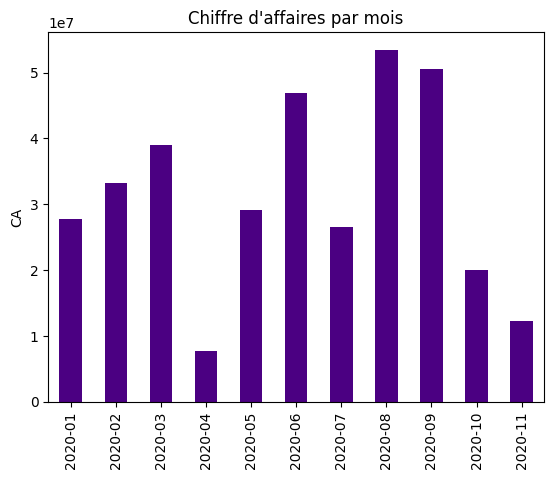

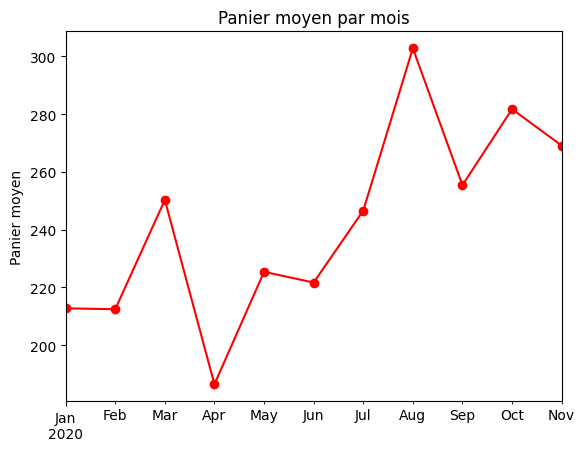

In [ ]:
# Graphique 1 : CA par mois
par_mois["ca"].plot(kind="bar", color='indigo', title="Chiffre d'affaires par mois")
plt.ylabel("CA")
plt.xlabel("")
plt.show()

# Graphique 2 : panier moyen par mois -> les clients achètent-ils plus cher à certaines périodes ?
par_mois["panier_moyen"].plot(marker="o", color='red', title="Panier moyen par mois")
plt.ylabel("Panier moyen")
plt.xlabel("")
plt.show()

### 3.2 Par jour de la semaine

**Ce qu'on cherche :** y a-t-il des jours où l'on vend plus ? Utile pour programmer les promotions et les campagnes marketing.

,ca,commandes,part_ca_%
weekday,,,
Monday,48560773.66,203690,14.004985
Tuesday,49431257.86,209651,14.256034
Wednesday,46543563.19,199341,13.423219
Thursday,45343954.56,192894,13.077251
Friday,53112920.62,210680,15.317830
Saturday,52890317.49,210174,15.253631
Sunday,50856416.05,197808,14.667051


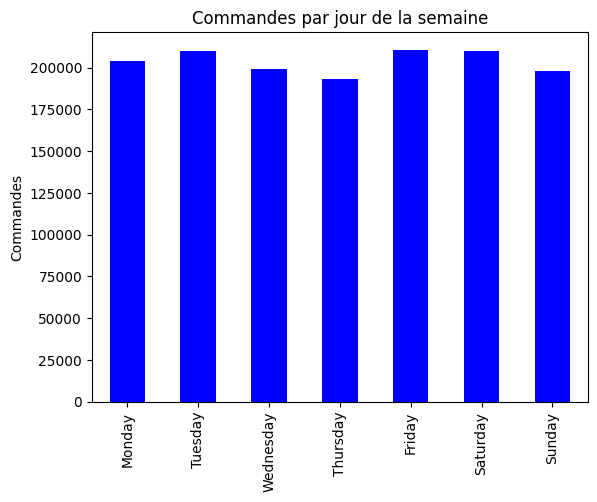

In [ ]:
# Ordre des jours pour que le graphique ne soit pas trié par ordre alphabétique
ordre_jours = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

par_jour_sem = (df.groupby("weekday")
                  .agg(ca=("price", "sum"), commandes=("order_id", "nunique"))
                  .reindex(ordre_jours))

# Part de chaque jour dans le CA total (en %)
par_jour_sem["part_ca_%"] = par_jour_sem["ca"] / par_jour_sem["ca"].sum() * 100
display(par_jour_sem)

par_jour_sem["commandes"].plot(kind="bar", color='blue', title="Commandes par jour de la semaine")
plt.ylabel("Commandes")
plt.xlabel("")
plt.show()

### 3.3 Par heure

**Ce qu'on cherche :** à quelles heures les clients commandent-ils ?

⚠️ Les heures sont en **UTC**. Le Kazakhstan est à UTC+6 (Almaty, Nour-Soultan en 2020) : 10 h UTC = 16 h heure locale. On ajoute donc 6 heures pour lire l'heure locale.

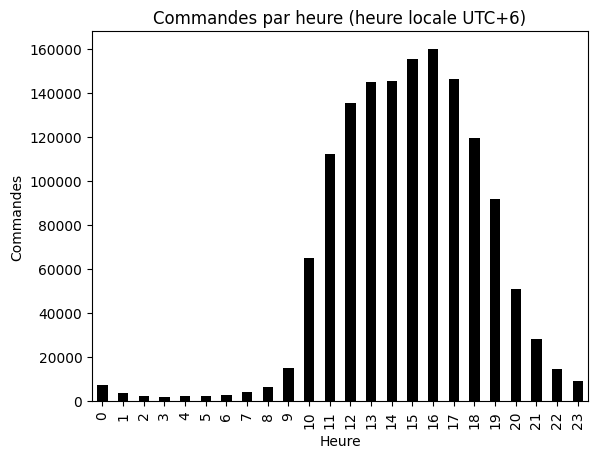

In [ ]:
# Conversion en heure locale du Kazakhstan (UTC+6) ; le % 24 fait repasser 25 h -> 1 h
df["hour_local"] = (df["hour"] + 6) % 24

par_heure = df.groupby("hour_local")["order_id"].nunique()

par_heure.plot(kind="bar", color='black', title="Commandes par heure (heure locale UTC+6)")
plt.ylabel("Commandes")
plt.xlabel("Heure")
plt.show()

## 4. Catégories : qui fait le chiffre d'affaires ?

### 4.1 Catégories principales

**Ce qu'on cherche :** quelles grandes familles de produits (electronics, appliances, computers...) rapportent le plus.

⚠️ Environ 40 % des lignes sont en `unknown`. On affiche leur poids **à part**, sinon les pourcentages des autres catégories seraient trompeurs.

In [ ]:
# Poids des "unknown" dans le CA (et pas seulement en nombre de lignes)
part_unknown = df.loc[df["category_main"] == "unknown", "price"].sum() / ca_total * 100
print(f"Part du CA sans catégorie connue : {part_unknown:.1f} %")

# On travaille sur les lignes dont la catégorie est connue
connu = df[df["category_main"] != "unknown"]

par_cat = (connu.groupby("category_main")
                .agg(ca=("price", "sum"),
                     articles=("order_id", "size"),
                     prix_median=("price", "median"))
                .sort_values("ca", ascending=False))

# Part de chaque catégorie dans le CA des catégories connues
par_cat["part_ca_%"] = par_cat["ca"] / par_cat["ca"].sum() * 100
display(par_cat)

Part du CA sans catégorie connue : 13.2 %


,ca,articles,prix_median,part_ca_%
category_main,,,,
electronics,1.472227e+08,544389,173.59,48.914405
appliances,1.030567e+08,605424,97.20,34.240341
computers,4.167457e+07,221270,39.33,13.846275
furniture,4.014682e+06,120447,22.66,1.333868
apparel,1.923148e+06,7618,368.03,0.638961
kids,1.113973e+06,4974,53.22,0.370115
construction,4.597860e+05,12527,11.55,0.152763
sport,4.453983e+05,1890,185.16,0.147983
auto,3.133015e+05,3228,81.00,0.104094


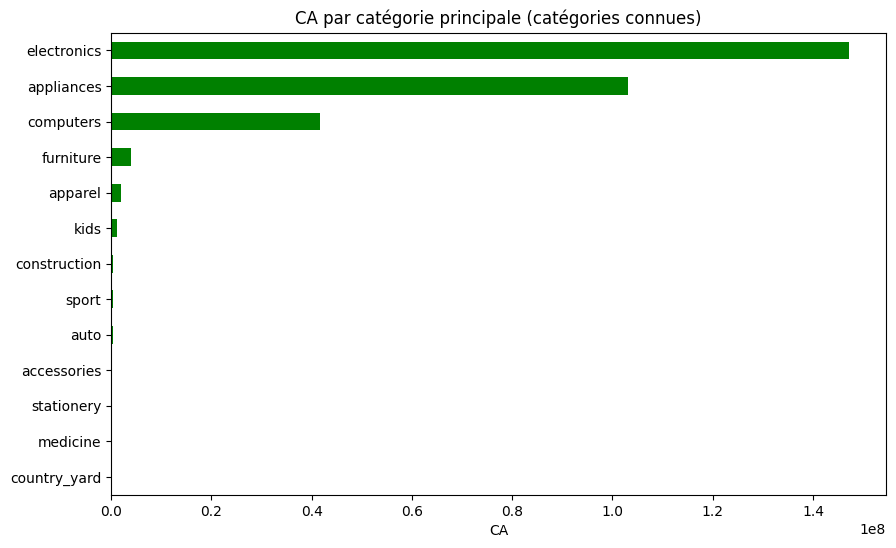

In [ ]:
# Graphique horizontal : plus lisible quand les noms de catégories sont longs
# On trie à l'envers pour avoir la plus grosse catégorie en haut
par_cat["ca"].sort_values().plot(kind="barh", color='green', figsize=(10, 6),
                                 title="CA par catégorie principale (catégories connues)")
plt.xlabel("CA")
plt.ylabel("")
plt.show()

### 4.2 Sous-catégories (top 15)

**Ce qu'on cherche :** à un niveau plus fin (smartphones, TV, réfrigérateurs...), quels produits portent vraiment le CA.

💡 On compare aussi **CA** et **nombre d'articles** : une catégorie peut vendre beaucoup d'articles mais rapporter peu (petits prix), ou l'inverse.

,ca,articles,prix_median,part_ca_%
category_code,,,,
electronics.smartphone,1.018990e+08,354727,174.28,33.855704
appliances.kitchen.refrigerators,3.135578e+07,77008,351.83,10.417883
computers.notebook,3.123993e+07,71078,393.50,10.379392
electronics.video.tv,2.901027e+07,70979,370.35,9.638592
appliances.kitchen.washer,1.833994e+07,55873,335.63,6.093402
appliances.environment.vacuum,9.170102e+06,65950,104.14,3.046744
appliances.environment.air_conditioner,7.221807e+06,28444,231.46,2.399428
appliances.kitchen.hood,6.916087e+06,31991,208.31,2.297853
electronics.tablet,5.383582e+06,19487,185.16,1.788682


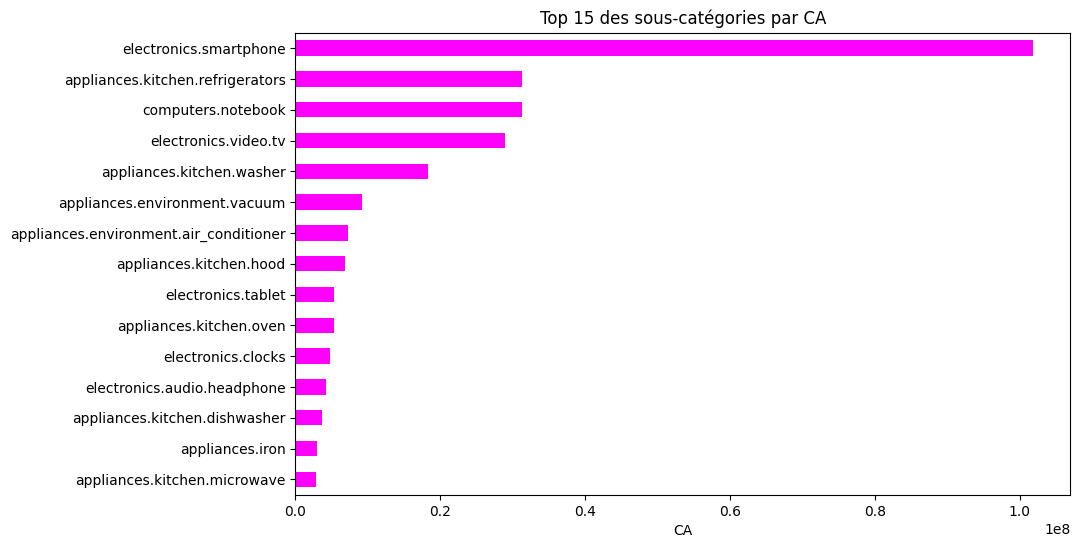

In [ ]:
par_sous_cat = (connu.groupby("category_code")
                     .agg(ca=("price", "sum"),
                          articles=("order_id", "size"),
                          prix_median=("price", "median"))
                     .sort_values("ca", ascending=False))
par_sous_cat["part_ca_%"] = par_sous_cat["ca"] / par_sous_cat["ca"].sum() * 100

top15 = par_sous_cat.head(15)
display(top15)

top15["ca"].sort_values().plot(kind="barh", color='Magenta', figsize=(10, 6),
                               title="Top 15 des sous-catégories par CA")
plt.xlabel("CA")
plt.ylabel("")
plt.show()

### 4.3 Évolution des catégories dans le temps

**Ce qu'on cherche :** toutes les catégories suivent-elles la même tendance ? Certaines ont-elles mieux résisté au confinement, ou ont-elles décollé à un moment précis (télétravail, été...) ?

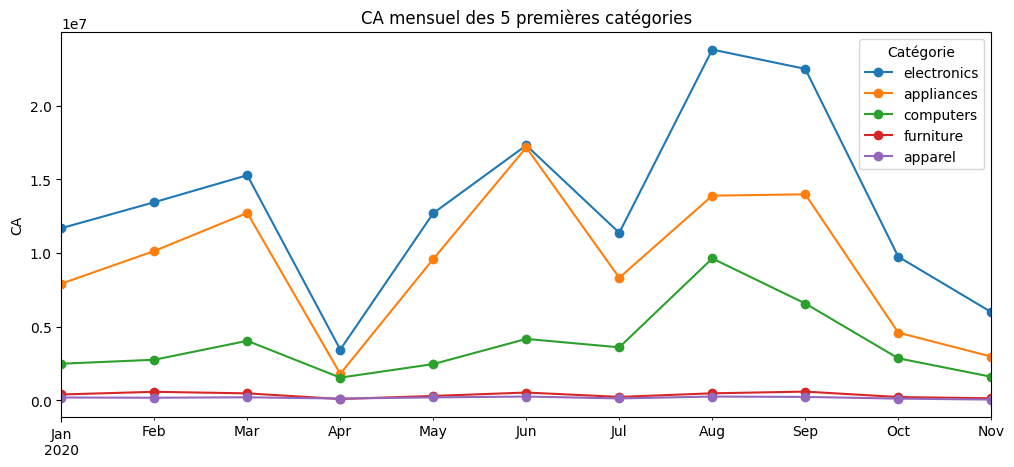

In [ ]:
# Tableau croisé : une ligne par mois, une colonne par catégorie principale, CA dans les cases
ca_cat_mois = connu.pivot_table(index="month", columns="category_main",
                                values="price", aggfunc="sum")

# On garde les 5 plus grosses catégories pour que le graphique reste lisible
top5 = par_cat.head(5).index
ca_cat_mois[top5].plot(marker="o", figsize=(12, 5), title="CA mensuel des 5 premières catégories")
plt.ylabel("CA")
plt.xlabel("")
plt.legend(title="Catégorie")
plt.show()

## 5. Marques

**Ce qu'on cherche :** quelles marques pèsent le plus dans le CA. Utile pour négocier avec les fournisseurs et choisir les marques à mettre en avant.

,ca,articles,prix_median,part_ca_%
brand,,,,
samsung,89530122.01,356343,162.01,27.081168
apple,47508355.08,74026,532.38,14.370379
lg,25988163.20,55321,416.64,7.860928
bosch,11024921.88,33728,300.90,3.334830
huawei,10642680.51,56648,162.01,3.219209
asus,10606186.69,20524,509.24,3.208171
lenovo,10493659.79,19586,486.09,3.174134
ava,8495886.71,117447,18.50,2.569845
beko,8441977.75,32003,262.25,2.553539


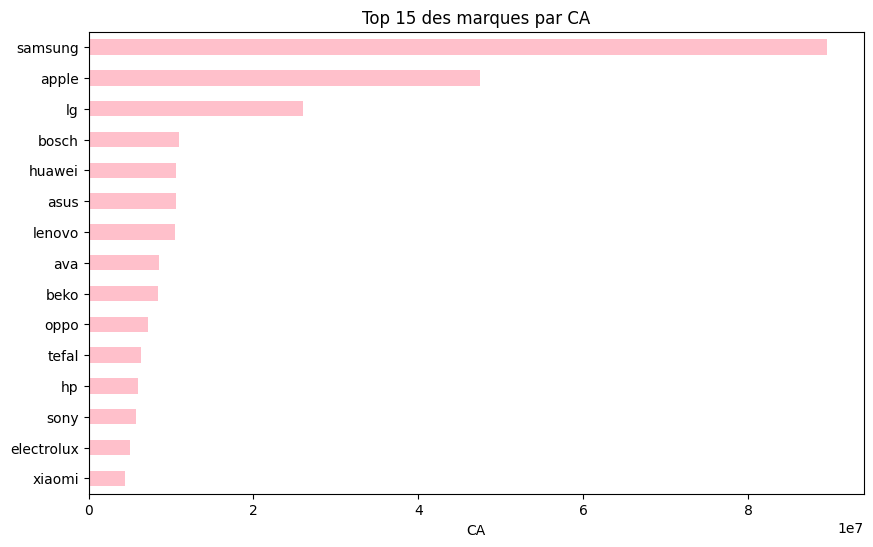

In [ ]:
# On exclut les marques inconnues
marques = df[df["brand"] != "unknown"]

par_marque = (marques.groupby("brand")
                     .agg(ca=("price", "sum"),
                          articles=("order_id", "size"),
                          prix_median=("price", "median"))
                     .sort_values("ca", ascending=False))
par_marque["part_ca_%"] = par_marque["ca"] / par_marque["ca"].sum() * 100

display(par_marque.head(15))

par_marque.head(15)["ca"].sort_values().plot(kind="barh", color='pink', figsize=(10, 6),
                                             title="Top 15 des marques par CA")
plt.xlabel("CA")
plt.ylabel("")
plt.show()

### 5.1 Zoom : les marques de smartphones

**Ce qu'on cherche :** les smartphones sont la plus grosse sous-catégorie. Quelles marques se partagent ce marché ?

In [ ]:
smartphones = df[df["category_code"] == "electronics.smartphone"]

parts_smartphones = (smartphones.groupby("brand")["price"].sum()
                                .sort_values(ascending=False))

# Part de marché en % du CA smartphones
parts_smartphones = parts_smartphones / parts_smartphones.sum() * 100
print(parts_smartphones.head(10).round(1))

brand
samsung    44.0
apple      34.4
huawei      9.5
oppo        7.1
xiaomi      2.6
honor       1.5
vivo        0.6
sony        0.1
nokia       0.0
awax        0.0
Name: price, dtype: float64


## 6. Concentration des ventes (Pareto 80/20)

**Ce qu'on cherche :** la règle des 80/20 dit souvent que **20 % des produits font 80 % du CA**. Est-ce le cas ici ?

**Pourquoi c'est important :** si peu de produits font l'essentiel du CA, il faut absolument éviter qu'ils soient en rupture de stock.

**Méthode :** on trie les produits du plus gros CA au plus petit, puis on calcule le CA **cumulé** en %.

In [ ]:
# CA par produit, du plus grand au plus petit
ca_produit = df.groupby("product_id")["price"].sum().sort_values(ascending=False)

# CA cumulé en % : le 1er produit fait x %, les 2 premiers y %, etc.
ca_cumule_pct = ca_produit.cumsum() / ca_produit.sum() * 100

# Combien de produits faut-il pour atteindre 80 % du CA ?
nb_produits_80 = (ca_cumule_pct < 80).sum() + 1
pct_produits_80 = nb_produits_80 / len(ca_produit) * 100
print(f"{nb_produits_80:,} produits ({pct_produits_80:.1f} % du catalogue) font 80 % du CA")

1,593 produits (6.4 % du catalogue) font 80 % du CA


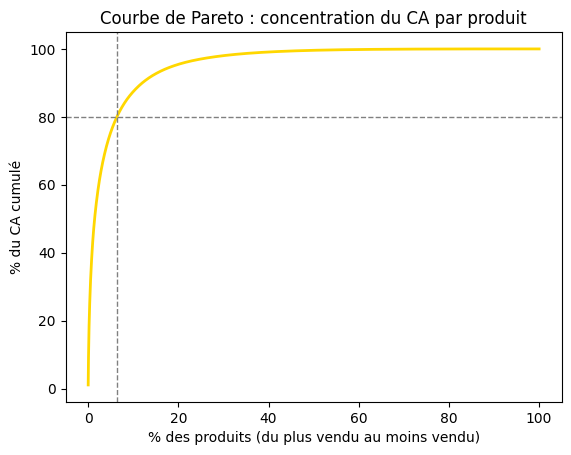

In [ ]:
# Courbe de Pareto : axe x = % des produits, axe y = % du CA cumulé
x = [i / len(ca_cumule_pct) * 100 for i in range(1, len(ca_cumule_pct) + 1)]
plt.plot(x, ca_cumule_pct.values, color='gold', linewidth=2)

# Lignes repères à 80 % du CA
plt.axhline(80, color="gray", linestyle="--", linewidth=1)
plt.axvline(pct_produits_80, color="gray", linestyle="--", linewidth=1)

plt.title("Courbe de Pareto : concentration du CA par produit")
plt.xlabel("% des produits (du plus vendu au moins vendu)")
plt.ylabel("% du CA cumulé")
plt.show()

## 7. Le panier : combien d'articles et quel montant par commande ?

**Ce qu'on cherche :** à quoi ressemble une commande type. Les clients achètent-ils un seul produit, ou plusieurs ?

💡 On regarde la **médiane** en plus de la moyenne : quelques très grosses commandes peuvent tirer la moyenne vers le haut.

In [ ]:
# Une ligne par commande : nombre d'articles et montant total
commandes = df.groupby("order_id").agg(
    nb_articles=("product_id", "size"),
    montant=("price", "sum")
)

print(commandes.describe())
print()
print(f"Panier moyen  : {commandes['montant'].mean():,.2f}")
print(f"Panier médian : {commandes['montant'].median():,.2f}")

        nb_articles       montant
count  1.424238e+06  1.424238e+06
mean   1.832139e+00  2.434559e+02
std    1.519883e+00  3.610697e+02
min    1.000000e+00  2.000000e-02
25%    1.000000e+00  2.914000e+01
50%    1.000000e+00  1.157200e+02
75%    2.000000e+00  3.050500e+02
max    6.100000e+01  5.230319e+04

Panier moyen  : 243.46
Panier médian : 115.72


1     60.8
2     20.0
3      9.1
4      4.4
5+     5.6
Name: proportion, dtype: float64


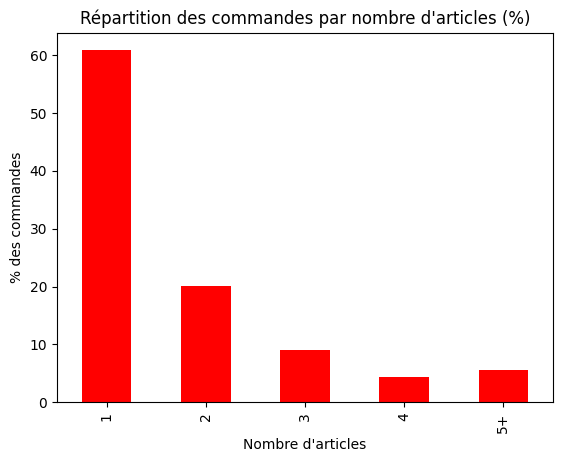

In [ ]:
# Répartition des commandes selon leur nombre d'articles
# On regroupe tout ce qui dépasse 5 articles dans "5+"
nb_art = commandes["nb_articles"].clip(upper=5)
repartition = nb_art.value_counts(normalize=True).sort_index() * 100
repartition.index = ["1", "2", "3", "4", "5+"]
print(repartition.round(1))

repartition.plot(kind="bar", color='red', title="Répartition des commandes par nombre d'articles (%)")
plt.ylabel("% des commandes")
plt.xlabel("Nombre d'articles")
plt.show()

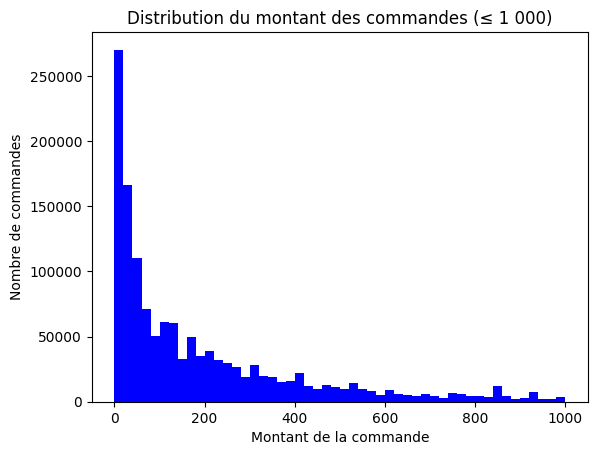

In [ ]:
# Distribution des montants de commande
# On coupe à 1 000 pour que les rares très grosses commandes n'écrasent pas le graphique
commandes.loc[commandes["montant"] <= 1000, "montant"].plot(
    kind="hist", bins=50, color='blue', title="Distribution du montant des commandes (≤ 1 000)")
plt.xlabel("Montant de la commande")
plt.ylabel("Nombre de commandes")
plt.show()

## 8. Clients (sur l'échantillon identifié)

⚠️ **Limite importante :** `user_id` n'est renseigné que pour environ 23 % des lignes. Cette partie porte donc sur un **échantillon**, à présenter comme tel.

### 8.1 Les clients reviennent-ils acheter ?

**Ce qu'on cherche :** le **taux de réachat** = part des clients qui ont passé au moins 2 commandes. Un taux faible signifie que l'enseigne dépend surtout de nouveaux clients.

In [ ]:
# On garde uniquement les lignes avec un client identifié
clients_df = df[df["user_id"].notna()]
print(f"Lignes avec client identifié : {len(clients_df):,} ({len(clients_df) / len(df) * 100:.1f} %)")

# Nombre de commandes différentes par client
cmd_par_client = clients_df.groupby("user_id")["order_id"].nunique()

taux_rachat = (cmd_par_client >= 2).mean() * 100
print(f"Clients identifiés : {len(cmd_par_client):,}")
print(f"Taux de réachat    : {taux_rachat:.1f} %")

# Répartition : combien de clients ont passé 1, 2, 3... commandes
print(cmd_par_client.clip(upper=10).value_counts().sort_index())

Lignes avec client identifié : 600,109 (23.0 %)
Clients identifiés : 234,359
Taux de réachat    : 31.9 %
order_id
1     159576
2      40745
3      15398
4       7484
5       4056
6       2356
7       1458
8        872
9        610
10      1804
Name: count, dtype: int64


### 9.2 Segmentation RFM

**Ce qu'on cherche :** classer les clients selon trois critères :
- **R – Récence** : combien de jours depuis le dernier achat ? (petit = mieux)
- **F – Fréquence** : combien de commandes ? (grand = mieux)
- **M – Montant** : combien dépensé au total ? (grand = mieux)

Chaque critère reçoit une note de 1 à 4, puis on regroupe les clients en segments (meilleurs clients, clients à risque...).

In [ ]:
# Date de référence : le lendemain de la dernière vente du jeu de données
date_ref = df["event_time"].max() + pd.Timedelta(days=1)

rfm = clients_df.groupby("user_id").agg(
    recence=("event_time", lambda d: (date_ref - d.max()).days),  # jours depuis le dernier achat
    frequence=("order_id", "nunique"),                            # nombre de commandes
    montant=("price", "sum")                                      # total dépensé
)

# Notes de 1 à 4 avec les quartiles (qcut découpe en 4 groupes de même taille)
# Récence : plus c'est récent, meilleure est la note -> étiquettes à l'envers
rfm["R"] = pd.qcut(rfm["recence"], 4, labels=[4, 3, 2, 1]).astype(int)
# Fréquence : beaucoup de clients ont 1 seule commande -> on classe d'abord avec rank()
# pour éviter que qcut plante à cause des valeurs identiques
rfm["F"] = pd.qcut(rfm["frequence"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M"] = pd.qcut(rfm["montant"], 4, labels=[1, 2, 3, 4]).astype(int)

display(rfm.head())

,recence,frequence,montant,R,F,M
user_id,,,,,,
1515915625439952115,136,1,416.64,1,1,3
1515915625440038436,25,2,56.43,4,3,1
1515915625440051468,5,5,7530.34,4,4,4
1515915625440099873,13,19,4935.60,4,4,4
1515915625440121544,130,2,182.83,1,3,2


In [ ]:
# Règles simples pour nommer les segments (tu peux les adapter)
def segment(ligne):
    if ligne["R"] >= 3 and ligne["F"] >= 3 and ligne["M"] >= 3:
        return "Meilleurs clients"       # récents, fréquents, gros acheteurs
    if ligne["R"] >= 3 and ligne["F"] <= 2:
        return "Nouveaux / occasionnels" # achat récent mais peu de commandes
    if ligne["R"] <= 2 and ligne["F"] >= 3:
        return "À risque"                # bons clients qui ne sont pas revenus depuis longtemps
    if ligne["R"] <= 2 and ligne["F"] <= 2:
        return "Perdus"                  # anciens et peu actifs
    return "Autres"

rfm["segment"] = rfm.apply(segment, axis=1)

# Taille et poids de chaque segment
resume_rfm = rfm.groupby("segment").agg(
    nb_clients=("montant", "size"),
    ca=("montant", "sum"),
    recence_moy=("recence", "mean"),
    frequence_moy=("frequence", "mean")
)
resume_rfm["part_clients_%"] = resume_rfm["nb_clients"] / resume_rfm["nb_clients"].sum() * 100
resume_rfm["part_ca_%"] = resume_rfm["ca"] / resume_rfm["ca"].sum() * 100
display(resume_rfm.sort_values("ca", ascending=False))

,nb_clients,ca,recence_moy,frequence_moy,part_clients_%,part_ca_%
segment,,,,,,
Meilleurs clients,44856,51708503.56,33.657593,2.955480,19.139867,43.722665
À risque,35414,32244772.73,136.715339,2.952815,15.111005,27.264904
Perdus,81674,21719830.45,153.553775,1.000000,34.849952,18.365429
Nouveaux / occasionnels,35506,9817794.87,51.144398,1.000000,15.150261,8.301539
Autres,36909,2773855.57,22.822509,1.318676,15.748915,2.345463


In [ ]:
import pandas as pd
from itertools import combinations
from collections import Counter

# 1. Chargement du fichier propre
df = pd.read_parquet("/content/kz_clean.parquet")

# 2. Table principale des ventes
df_pbi = df.drop(columns=["month"], errors="ignore")      # Power BI recréera le mois lui-même
df_pbi["hour_local"] = (df_pbi["hour"] + 6) % 24          # heure locale Kazakhstan (UTC+6)
df_pbi.to_csv("ventes_pbi.csv", index=False)
print("ventes_pbi.csv ✅")

# 3. Paires de sous-catégories achetées ensemble (même méthode que la partie 8)
connu = df[df["category_main"] != "unknown"]
cats_par_commande = connu.groupby("order_id")["category_code"].apply(lambda s: sorted(set(s)))
multi = cats_par_commande[cats_par_commande.apply(len) >= 2]
compteur = Counter()
for cats in multi:
    compteur.update(combinations(cats, 2))
paires = pd.DataFrame(compteur.most_common(50), columns=["paire", "nb_commandes"])
paires[["categorie_A", "categorie_B"]] = pd.DataFrame(paires["paire"].tolist())
paires.drop(columns="paire").to_csv("paires_produits.csv", index=False)
print("paires_produits.csv ✅")

# 4. Courbe de Pareto (même méthode que la partie 6)
ca_produit = df.groupby("product_id")["price"].sum().sort_values(ascending=False)
ca_cumule_pct = ca_produit.cumsum() / ca_produit.sum() * 100
x = [i / len(ca_cumule_pct) * 100 for i in range(1, len(ca_cumule_pct) + 1)]
pareto = pd.DataFrame({"pct_produits": x, "pct_ca_cumule": ca_cumule_pct.values})
pareto.iloc[::25].to_csv("pareto.csv", index=False)       # 1 point sur 25 suffit pour la courbe
print("pareto.csv ✅")

# 5. Segmentation RFM (même méthode que la partie 9)
clients_df = df[df["user_id"].notna()]
date_ref = df["event_time"].max() + pd.Timedelta(days=1)
rfm = clients_df.groupby("user_id").agg(
    recence=("event_time", lambda d: (date_ref - d.max()).days),
    frequence=("order_id", "nunique"),
    montant=("price", "sum")
)
rfm["R"] = pd.qcut(rfm["recence"], 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["frequence"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M"] = pd.qcut(rfm["montant"], 4, labels=[1, 2, 3, 4]).astype(int)

def segment(ligne):
    if ligne["R"] >= 3 and ligne["F"] >= 3 and ligne["M"] >= 3:
        return "Meilleurs clients"
    if ligne["R"] >= 3 and ligne["F"] <= 2:
        return "Nouveaux / occasionnels"
    if ligne["R"] <= 2 and ligne["F"] >= 3:
        return "À risque"
    if ligne["R"] <= 2 and ligne["F"] <= 2:
        return "Perdus"
    return "Autres"

rfm["segment"] = rfm.apply(segment, axis=1)
rfm.reset_index().to_csv("rfm_clients.csv", index=False)
print("rfm_clients.csv ✅")

ventes_pbi.csv ✅
paires_produits.csv ✅
pareto.csv ✅
rfm_clients.csv ✅


In [ ]:
import os
print(os.getcwd())

/content
